# Huấn luyện CNN nhận dạng hoạt động bằng notebook

Notebook trình bày trực tiếp toàn bộ quá trình: đọc chín kênh UCI HAR, chia theo người, chuẩn hóa, định nghĩa CNN-A/B/C, compile, callbacks, `model.fit()`, checkpoint và đánh giá validation. Không cần gọi CLI hoặc hàm huấn luyện trong `har_project`.

**Chạy từ trên xuống dưới.** Chọn kernel Python của `.venv` đã cài `requirements.txt`. Nếu dùng môi trường khác, cần các thư viện đó và bộ dữ liệu ở đường dẫn cấu hình bên dưới.

- `RUN_MODE = "inspect"`: mặc định; xem lại lịch sử và kết quả đã có, không huấn luyện hoặc ghi lại `results/`.
- `RUN_MODE = "smoke"`: chạy CNN-B seed 42 trong một epoch, kiểm tra notebook.
- `RUN_MODE = "train"`: chạy các mô hình trong `MODELS` với ba seed, tối đa 50 epoch và early stopping.

Các lượt mới được lưu dưới `notebook_runs/RUN_NAME/`. Đổi `RUN_NAME` trước mỗi đợt mới; notebook từ chối ghi đè. Bộ kết quả test chính thức đã khóa vẫn được giữ ở `results/`. Những lần chạy thêm sau khi đã xem test là tái chạy/khám phá, không thay thế bằng chứng đánh giá ban đầu.

## 1. Cấu hình và môi trường
Để chỉ huấn luyện mô hình cơ sở, đổi `MODELS` thành `["cnn_b"]`. Giữ các giá trị bên dưới khi tái chạy protocol đã chốt; ghi rõ nếu bạn thay đổi chúng.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform
from datetime import datetime, timezone

ROOT = Path.cwd().resolve()
if not (ROOT / "Dataset").is_dir() and (ROOT.parent / "Dataset").is_dir():
    ROOT = ROOT.parent
# Nếu dữ liệu đặt nơi khác, chỉnh DATA_DIR; ROOT là nơi lưu notebook_runs.
DATA_DIR = ROOT / "Dataset" / "UCI HAR Dataset"
SOURCE_RESULTS = ROOT / "results"
OUTPUT_BASE = ROOT / "notebook_runs"

RUN_MODE = "inspect"  # inspect | smoke | train
RUN_NAME = "har_cnn_notebook_v1"
MODELS = ["cnn_a", "cnn_b", "cnn_c"]
SEEDS = [42, 123, 2026]
LEARNING_RATE = 0.001
BATCH_SIZE = 64
MAX_EPOCHS = 50
PATIENCE = 8
DROPOUT = 0.3
VALIDATION_SUBJECTS = [5, 11, 19, 26]
NEW_RUN_ROOT = OUTPUT_BASE / RUN_NAME

if RUN_MODE not in {"inspect", "smoke", "train"}:
    raise ValueError("RUN_MODE phải là inspect, smoke hoặc train")
os.environ["MPLCONFIGDIR"] = str(ROOT / ".cache" / "matplotlib")
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
print("Project:", ROOT)
print("Mode:", RUN_MODE)
print("New run:", NEW_RUN_ROOT)


Project: E:\PPNCKH\SGU26_PPNCKH_Group
Mode: inspect
New run: E:\PPNCKH\SGU26_PPNCKH_Group\notebook_runs\har_cnn_notebook_v1


In [2]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print("TensorFlow đã khởi tạo; giữ cấu hình thread hiện có. Restart kernel nếu cần đổi.")
tf.config.experimental.enable_op_determinism()
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())


Python: 3.12.13
TensorFlow: 2.21.0


Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Đọc chín kênh tín hiệu
Mỗi dòng là một cửa sổ 128 thời điểm. Ghép theo chiều kênh thành `(7352, 128, 9)`. Phần huấn luyện chỉ đọc train chính thức, không nạp tín hiệu/nhãn test. Các chuỗi này đã được dataset lọc nhiễu và phân đoạn.

In [3]:
CHANNELS = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z",
]
ACTIVITIES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
train_dir = DATA_DIR / "train"
raw_labels = np.loadtxt(train_dir / "y_train.txt", ndmin=1)
raw_subjects = np.loadtxt(train_dir / "subject_train.txt", ndmin=1)
if raw_labels.ndim != 1 or raw_subjects.shape != raw_labels.shape:
    raise ValueError("Nhãn và subject không cùng số dòng")
if not np.isin(raw_labels, np.arange(1, 7)).all() or not np.isin(raw_subjects, np.arange(1, 31)).all():
    raise ValueError("Nhãn hoặc subject không hợp lệ")
y = raw_labels.astype(np.int64) - 1
subjects = raw_subjects.astype(np.int64)

signal_files = [train_dir / "Inertial Signals" / f"{channel}_train.txt" for channel in CHANNELS]
signals = []
for path in signal_files:
    signal = np.loadtxt(path, dtype=np.float32, ndmin=2)
    if signal.shape != (len(y), 128) or not np.isfinite(signal).all():
        raise ValueError(f"Kích thước hoặc giá trị không hợp lệ: {path.name}")
    signals.append(signal)
X = np.stack(signals, axis=-1)
print("X:", X.shape, X.dtype)
print("y:", y.shape, "labels:", np.unique(y))
print("Subjects:", np.unique(subjects))


X: (7352, 128, 9) float32
y: (7352,) labels: [0 1 2 3 4 5]
Subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]


## 3. Chia fit-train và validation theo người
Validation cố định gồm người 5, 11, 19, 26. Không tách ngẫu nhiên các cửa sổ chồng lấn. Các index được giữ để truy nguyên nhãn và người tham gia.

In [4]:
if not set(VALIDATION_SUBJECTS).issubset(set(subjects.tolist())):
    raise ValueError("Thiếu người validation trong dữ liệu train")
validation_mask = np.isin(subjects, VALIDATION_SUBJECTS)
fit_indices = np.flatnonzero(~validation_mask)
validation_indices = np.flatnonzero(validation_mask)
x_fit_raw, y_fit = X[fit_indices], y[fit_indices]
x_val_raw, y_val = X[validation_indices], y[validation_indices]
if set(subjects[fit_indices]) & set(subjects[validation_indices]):
    raise ValueError("Trùng người giữa fit-train và validation")
if any(set(labels.tolist()) != set(range(6)) for labels in (y_fit, y_val)):
    raise ValueError("Mỗi tập cần đủ sáu lớp")
print("Fit-train:", x_fit_raw.shape, "Validation:", x_val_raw.shape)
distribution = pd.DataFrame({
    "activity": ACTIVITIES,
    "fit_train": np.bincount(y_fit, minlength=6),
    "validation": np.bincount(y_val, minlength=6),
}).set_index("activity")
display(distribution)


Fit-train: (5982, 128, 9) Validation: (1370, 128, 9)


,fit_train,validation
activity,,
WALKING,1000,226
WALKING_UPSTAIRS,877,196
WALKING_DOWNSTAIRS,804,182
SITTING,1038,248
STANDING,1124,250
LAYING,1139,268


## 4. Chuẩn hóa chỉ bằng fit-train
Mean/std được tính theo từng kênh trên trục mẫu và thời gian của fit-train. Validation dùng lại chính thống kê đó. Việc này tránh fit thống kê từ người validation.

In [5]:
mean = x_fit_raw.mean(axis=(0, 1), keepdims=True, dtype=np.float64)
std = np.maximum(x_fit_raw.std(axis=(0, 1), keepdims=True, dtype=np.float64), 1e-8)
x_fit = ((x_fit_raw - mean) / std).astype(np.float32)
x_val = ((x_val_raw - mean) / std).astype(np.float32)
if not np.isfinite(x_fit).all() or not np.isfinite(x_val).all():
    raise ValueError("Dữ liệu chuẩn hóa có NaN/Inf")
print("Mean fit-train sau chuẩn hóa:", np.round(x_fit.mean(axis=(0, 1)), 5))
print("Std fit-train sau chuẩn hóa:", np.round(x_fit.std(axis=(0, 1)), 5))


Mean fit-train sau chuẩn hóa: [-0. -0. -0.  0. -0.  0.  0.  0.  0.]


Std fit-train sau chuẩn hóa: [0.9997  0.99948 0.99942 0.99966 0.99957 0.99961 0.99981 0.99964 0.99981]


## 5. Định nghĩa và compile CNN trực tiếp
CNN-A có một Conv, CNN-B có hai Conv, CNN-C có ba Conv. Tất cả dùng phần cuối GAP → Dense64 → Dropout → Softmax6. Tăng độ sâu đồng thời đổi số tham số và receptive field; kết quả không cô lập riêng ảnh hưởng của độ sâu.

In [6]:
def build_cnn(name):
    if name not in {"cnn_a", "cnn_b", "cnn_c"}:
        raise ValueError("Mô hình phải là cnn_a, cnn_b hoặc cnn_c")
    layers = tf.keras.layers
    model = tf.keras.Sequential(name=name)
    model.add(layers.Input(shape=(128, 9)))
    model.add(layers.Conv1D(64, kernel_size=5, padding="same", activation="relu"))
    model.add(layers.MaxPooling1D(pool_size=2))
    if name in {"cnn_b", "cnn_c"}:
        model.add(layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"))
    if name == "cnn_c":
        model.add(layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.GlobalAveragePooling1D())
    model.add(layers.Dense(64, activation="relu"))
    model.add(layers.Dropout(DROPOUT))
    model.add(layers.Dense(6, activation="softmax"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


In [7]:
tf.keras.utils.set_random_seed(42)
example_model = build_cnn("cnn_b")
example_model.summary()


Model: "cnn_b"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 64, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,294 (141.77 KB)

 Trainable params: 36,294 (141.77 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Dataset, callbacks và cách lưu bằng chứng
Chỉ xáo trộn fit-train. Early stopping và checkpoint cùng theo `val_loss`. Khi chạy mới, mỗi seed phải có mô hình và optimizer mới. Các hàm dưới được định nghĩa ngay trong notebook.

In [8]:
def make_tf_dataset(x, labels, seed, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((x, labels))
    if training:
        dataset = dataset.shuffle(len(labels), seed=seed, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.deterministic = True
    options.threading.private_threadpool_size = 2
    options.threading.max_intra_op_parallelism = 2
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)


def make_callbacks(folder):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(str(folder / "model.keras"), monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.CSVLogger(str(folder / "history.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
    ]


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def save_json(path, payload):
    Path(path).write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")


In [9]:
def validate_output(run_root, output_base, source_results):
    run_root = Path(run_root).resolve()
    output_base = Path(output_base).resolve()
    source_results = Path(source_results).resolve()
    if run_root == source_results or run_root.is_relative_to(source_results):
        raise ValueError("Không ghi lượt huấn luyện mới vào results gốc")
    if run_root == output_base or not run_root.is_relative_to(output_base):
        raise ValueError("RUN_NAME phải nằm bên trong notebook_runs")
    return run_root


def create_run_folder(folder):
    Path(folder).mkdir(parents=True, exist_ok=False)


def validate_seeds(seeds):
    if not seeds or any(not isinstance(seed, int) or isinstance(seed, bool) or not 0 <= seed < 2**32 for seed in seeds):
        raise ValueError("SEEDS phải gồm các số nguyên từ 0 đến 2**32-1")
    if len(set(seeds)) != len(seeds):
        raise ValueError("SEEDS không được trùng lặp")


## 7. Huấn luyện bằng `model.fit()`

Đây là ô thực sự huấn luyện, không gọi script ngoài. Để thử, đổi `RUN_MODE` ở phần 1 thành `smoke`, chọn `RUN_NAME` mới rồi **Save → Restart Kernel → Run All**. Để chạy đủ mô hình và seed, chọn `train`. Có thể đổi `MODELS=["cnn_b"]` để chạy riêng mô hình cơ sở.

`smoke` chỉ dùng kiểm tra pipeline và không tham gia kết luận chính thức. Các lượt notebook mới chỉ đánh giá validation; không sử dụng test đã xem để chọn lại mô hình của đợt gốc.

In [10]:
if RUN_MODE == "inspect":
    print("Chế độ inspect: không gọi model.fit(), đang đọc lịch sử có sẵn ở phần sau.")
else:
    run_root = validate_output(NEW_RUN_ROOT, OUTPUT_BASE, SOURCE_RESULTS)
    chosen_models = ["cnn_b"] if RUN_MODE == "smoke" else MODELS
    chosen_seeds = [42] if RUN_MODE == "smoke" else SEEDS
    if not chosen_models or len(set(chosen_models)) != len(chosen_models) or any(name not in {"cnn_a", "cnn_b", "cnn_c"} for name in chosen_models):
        raise ValueError("MODELS cần là danh sách hợp lệ, không trùng lặp")
    validate_seeds(chosen_seeds)
    create_run_folder(run_root)  # Từ chối cả đợt nếu RUN_NAME đã tồn tại.
    notebook_path = ROOT / "notebooks" / "02_har_training.ipynb"
    source_snapshot_sha256 = None
    if notebook_path.is_file():
        snapshot_path = run_root / "notebook_source.ipynb"
        snapshot_path.write_bytes(notebook_path.read_bytes())
        source_snapshot_sha256 = sha256_file(snapshot_path)
    else:
        print("Không tìm thấy notebook trên đĩa để snapshot; lưu notebook và giữ mã cùng kết quả.")
    np.savez(run_root / "normalization.npz", mean=mean, std=std, channels=np.array(CHANNELS))
    save_json(run_root / "split.json", {
        "fit_train_indices_in_official_train": fit_indices.tolist(),
        "validation_indices_in_official_train": validation_indices.tolist(),
        "validation_subjects": VALIDATION_SUBJECTS,
    })
    source_paths = signal_files + [train_dir / "y_train.txt", train_dir / "subject_train.txt"]
    save_json(run_root / "experiment.json", {
        "mode": RUN_MODE, "models": chosen_models, "seeds": chosen_seeds,
        "kind": "smoke" if RUN_MODE == "smoke" else "notebook_reproduction",
        "test_evaluated": False, "started_utc": datetime.now(timezone.utc).isoformat(),
        "notebook_on_disk_sha256": source_snapshot_sha256,
        "snapshot_scope": "Notebook saved on disk; runtime model/seed/hyperparameters recorded separately",
        "python": sys.version, "tensorflow": tf.__version__, "numpy": np.__version__,
        "devices": [str(device) for device in tf.config.list_physical_devices()],
        "input_sha256": {p.relative_to(DATA_DIR).as_posix(): sha256_file(p) for p in source_paths},
    })
    for model_name in chosen_models:
        for seed in chosen_seeds:
            print(f"\n--- {model_name}, seed {seed}, mode {RUN_MODE} ---")
            folder = run_root / ("smoke" if RUN_MODE == "smoke" else "runs") / f"{model_name}_seed{seed}"
            create_run_folder(folder)
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(seed)
            model = build_cnn(model_name)
            epochs = 1 if RUN_MODE == "smoke" else MAX_EPOCHS
            config = {
                "model": model_name, "seed": seed, "batch_size": BATCH_SIZE, "epochs_max": epochs,
                "learning_rate": LEARNING_RATE, "patience": PATIENCE, "dropout_rate": DROPOUT,
                "channels": CHANNELS, "parameters": model.count_params(), "test_evaluated": False,
            }
            save_json(folder / "config.json", config)
            (folder / "architecture.json").write_text(model.to_json(), encoding="utf-8")
            started = time.perf_counter()
            history = model.fit(
                make_tf_dataset(x_fit, y_fit, seed, training=True),
                validation_data=make_tf_dataset(x_val, y_val, seed),
                epochs=epochs,
                callbacks=make_callbacks(folder),
                shuffle=False,  # Dataset đã tự xáo trộn fit-train phía trên.
                verbose=2,
            )
            training_seconds = time.perf_counter() - started
            if not all(np.isfinite(v) for values in history.history.values() for v in values):
                raise ValueError("Lịch sử có NaN/Inf; không đưa lượt này vào bảng kết quả")
            # Luôn lấy checkpoint val_loss tốt nhất, không lấy mặc định epoch cuối.
            best_model = tf.keras.models.load_model(folder / "model.keras")
            probabilities = best_model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)
            in_memory = model.predict(x_val[:64], batch_size=BATCH_SIZE, verbose=0)
            np.testing.assert_allclose(probabilities[:64], in_memory, rtol=1e-5, atol=1e-6)
            if not np.isfinite(probabilities).all() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
                raise ValueError("Xác suất validation không hợp lệ")
            predictions = probabilities.argmax(axis=1)
            metrics = {
                "model": model_name, "seed": seed, "split": "validation",
                "kind": "smoke" if RUN_MODE == "smoke" else "notebook_reproduction",
                "accuracy": float(accuracy_score(y_val, predictions)),
                "macro_f1": float(f1_score(y_val, predictions, labels=list(range(6)), average="macro", zero_division=0)),
                "epochs_run": len(history.history["loss"]),
                "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
                "parameters": model.count_params(), "training_seconds": training_seconds,
                "checkpoint_reload_verified": True, "test_evaluated": False,
                "report": classification_report(y_val, predictions, labels=list(range(6)), target_names=ACTIVITIES, output_dict=True, zero_division=0),
                "confusion_matrix": confusion_matrix(y_val, predictions, labels=list(range(6))).tolist(),
            }
            save_json(folder / "validation_metrics.json", metrics)
            frame = pd.DataFrame({"sample_index_in_official_train": validation_indices, "subject_id": subjects[validation_indices], "y_true": y_val, "y_pred": predictions})
            for index, activity in enumerate(ACTIVITIES):
                frame[f"p_{activity}"] = probabilities[:, index]
            frame.to_csv(folder / "validation_predictions.csv", index=False)
            save_json(folder / "checkpoint_sha256.json", {"model.keras": sha256_file(folder / "model.keras")})
            print(f"Validation Accuracy={metrics['accuracy']:.4f}, Macro-F1={metrics['macro_f1']:.4f}, time={training_seconds:.2f}s")


Chế độ inspect: không gọi model.fit(), đang đọc lịch sử có sẵn ở phần sau.


## 8. Bảng kết quả từng mô hình và seed
Chế độ inspect đọc chín lượt gốc. Các chế độ còn lại chỉ đọc đợt notebook vừa chạy. Bảng luôn ghi rõ `kind` và `split`, không trộn smoke với kết quả chính thức.

In [11]:
if RUN_MODE == "inspect":
    run_folders = sorted((SOURCE_RESULTS / "runs").glob("cnn_*_seed*"))
else:
    run_folders = sorted((NEW_RUN_ROOT / ("smoke" if RUN_MODE == "smoke" else "runs")).glob("cnn_*_seed*"))
records = []
for folder in run_folders:
    path = folder / "validation_metrics.json"
    if path.exists():
        row = json.loads(path.read_text(encoding="utf-8"))
        records.append({key: row[key] for key in ("kind", "model", "seed", "split", "epochs_run", "best_epoch", "accuracy", "macro_f1", "parameters", "training_seconds")})
validation_table = pd.DataFrame(records)
if not validation_table.empty:
    display(validation_table.sort_values(["model", "seed"]))
    validation_summary = validation_table.groupby("model").agg(
        n_runs=("seed", "count"), accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
        macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    )
    display(validation_summary)
    print("SD là độ lệch chuẩn mẫu qua seed. Một lượt chạy có SD=NaN, không tự thay bằng 0.")
else:
    print("Chưa có lượt hoàn tất để hiển thị.")


,kind,model,seed,split,epochs_run,best_epoch,accuracy,macro_f1,parameters,training_seconds
2,official,cnn_a,42,validation,19,11,0.948905,0.952391,7494,30.281830
0,official,cnn_a,123,validation,17,9,0.942336,0.945840,7494,27.837602
1,official,cnn_a,2026,validation,19,11,0.945985,0.949958,7494,30.096381
5,official,cnn_b,42,validation,10,2,0.946715,0.950433,36294,22.560213
3,official,cnn_b,123,validation,20,12,0.957664,0.959491,36294,47.481765
4,official,cnn_b,2026,validation,16,8,0.946715,0.950584,36294,35.372130
8,official,cnn_c,42,validation,11,3,0.937226,0.939245,85574,70.193922
6,official,cnn_c,123,validation,11,3,0.950365,0.954048,85574,59.272066
7,official,cnn_c,2026,validation,10,2,0.952555,0.956242,85574,85.892310


,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
model,,,,,
cnn_a,3,0.945742,0.003291,0.949397,0.003311
cnn_b,3,0.950365,0.006321,0.953502,0.005187
cnn_c,3,0.946715,0.008290,0.949845,0.009245


SD là độ lệch chuẩn mẫu qua seed. Một lượt chạy có SD=NaN, không tự thay bằng 0.


## 9. Learning curves và checkpoint
Các đường dưới được vẽ từ `history.csv` thực tế. Đường dọc là epoch có validation loss nhỏ nhất. Không chọn checkpoint bằng test Accuracy.

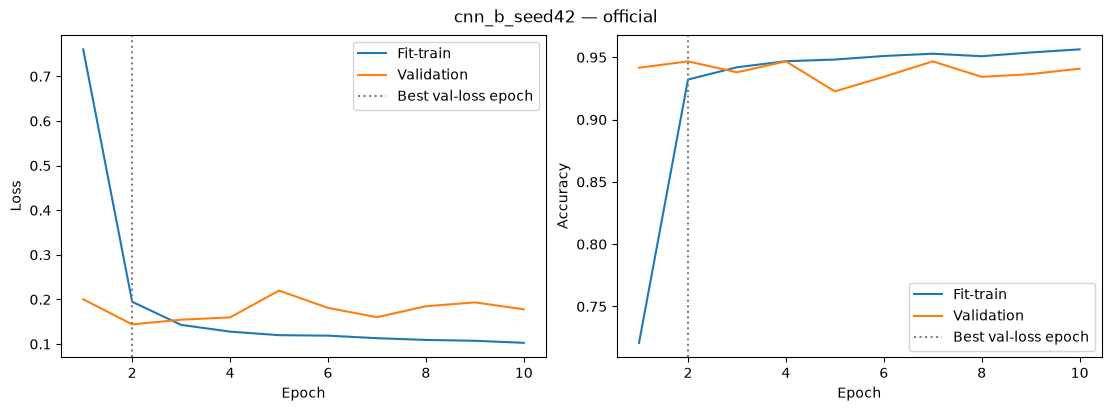

Checkpoint: E:\PPNCKH\SGU26_PPNCKH_Group\results\runs\cnn_b_seed42\model.keras


In [12]:
completed = [folder for folder in run_folders if (folder / "validation_metrics.json").exists()]
if completed:
    # Ưu tiên CNN-B seed 42 để minh họa theo quy ước của đồ án.
    preferred = next((folder for folder in completed if folder.name == "cnn_b_seed42"), completed[0])
    history_frame = pd.read_csv(preferred / "history.csv")
    saved_metrics = json.loads((preferred / "validation_metrics.json").read_text(encoding="utf-8"))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(history_frame["epoch"] + 1, history_frame[metric], marker="." if len(history_frame) == 1 else None, label="Fit-train")
        ax.plot(history_frame["epoch"] + 1, history_frame[f"val_{metric}"], marker="." if len(history_frame) == 1 else None, label="Validation")
        ax.axvline(saved_metrics["best_epoch"], color="gray", linestyle=":", label="Best val-loss epoch")
        ax.set(xlabel="Epoch", ylabel=metric.capitalize())
        ax.legend()
    fig.suptitle(f"{preferred.name} — {saved_metrics['kind']}")
    plt.show()
    if RUN_MODE != "inspect":
        fig.savefig(preferred / "learning_curves.png", dpi=180)
    plt.close(fig)
    print("Checkpoint:", preferred / "model.keras")


## 10. Đọc kết quả test gốc để trình bày

Phần này chỉ đọc bảng đã tính của đợt gốc, không gọi `predict()` trên test. Nó độc lập với đợt huấn luyện notebook mới. Nếu bạn thay đổi mô hình sau khi đã xem test này, cần một thiết kế đánh giá mới để xác nhận cải tiến; không thay kết quả gốc bằng số validation của lần chạy mới.

In [13]:
if RUN_MODE == "inspect" and (SOURCE_RESULTS / "test_evaluation_status.json").exists():
    status = json.loads((SOURCE_RESULTS / "test_evaluation_status.json").read_text(encoding="utf-8"))
    lock_path = SOURCE_RESULTS / "protocol_lock.json"
    if status.get("state") != "completed" or status.get("lock_sha256") != sha256_file(lock_path):
        raise ValueError("Bộ kết quả test chưa hoàn tất hoặc không khớp lock")
    for relative in ("metrics_summary.csv", "metrics_per_run.csv"):
        if sha256_file(SOURCE_RESULTS / relative) != status["result_sha256"].get(relative):
            raise ValueError(f"Bảng test đã thay đổi: {relative}")
    display(pd.read_csv(SOURCE_RESULTS / "metrics_summary.csv"))
    lock = json.loads(lock_path.read_text(encoding="utf-8"))
    print("Cấu hình đã chọn từ validation trước test:", lock["selected_model"])
else:
    print("Đợt notebook này chỉ đánh giá validation; không tính điểm test.")


,model,n_runs,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,parameters,training_seconds_mean
0,cnn_a,3,0.906911,0.003079,0.908219,0.003023,7494,29.405271
1,cnn_b,3,0.915281,0.004519,0.916081,0.004601,36294,35.138036
2,cnn_c,3,0.912566,0.000784,0.912694,0.000926,85574,71.786099


Cấu hình đã chọn từ validation trước test: cnn_b


## Cách dùng trong báo cáo và thuyết trình

Giải thích lần lượt shape dữ liệu, lý do tách người, nguồn thống kê chuẩn hóa, kiến trúc CNN-B, loss/optimizer, early stopping, checkpoint và learning curves. Bảng từng seed hỗ trợ trình bày biến động huấn luyện. Accuracy validation không được ghi thành Accuracy test. So sánh độ sâu phải kèm số tham số; chưa thể khẳng định khác biệt có ý nghĩa thống kê từ ba seed trên một split.

**Chạy mới bằng notebook:** chọn `RUN_MODE="smoke"` hoặc `"train"`, đặt `RUN_NAME` chưa dùng, rồi Restart Kernel và Run All. Với `train`, chọn `MODELS=["cnn_b"]` để bắt đầu từ mô hình cơ sở hoặc giữ cả ba mô hình cho E2. Đường dẫn checkpoint, cấu hình, lịch sử và dự đoán xuất hiện trong output ngay bên trên.

Lưu notebook trước khi chạy để đợt mới giữ được bản mã trên đĩa và SHA-256 trong `experiment.json`. Cấu hình runtime thực tế được ghi riêng để đối chiếu với snapshot.